# spectraPyle on ESA DataLabs


<br>
<br>
<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px;" src="Elsa-Color.png" />


<div style="width: 70%;">

Copyright (c) Salvatore Quai, 2026. 

This file is subject to the terms and conditions defined in LICENSE.txt, which forms part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in LICENSE.txt.

**version** v0.3

**Last modified:** November 12, 2026

## This notebook:

Contains a short end-to-end tutorial for building a Euclid spectroscopic catalogue and stacking spectra directly from the DataLabs repository with **spectraPyle**.
Please, refer to the [spectraPyle guide](https://spectrapyle.readthedocs.io/en/latest/index.html) for complete documentation and tutorials.

> **Read-only notebook**  
> The copy distributed in the shared DataLabs area is read-only. **Make a copy in your personal workspace before editing it** or adapting the query/configuration.

The notebook will:
1. install spectraPyle (first use only),
2. authenticate to the Euclid Science Archive when needed,
3. select the Euclid data release and survey tables,
4. query a small Euclid sample and save the result as a catalogue ready for spectraPyle,
5. launch the GUI, configure the stacked params and generate stacked spectra,
6. view generated stacked spectra,
7. Further documentation.
   
The DataLabs workflow uses the SIR metadata columns **`datalabs_path`**, **`file_name`**, and **`hdu_index`** to read spectra directly from the repository: no manual spectrum download is required.

> **Environment**: Run this notebook using the **EUCLID-TOOLS** Jupyter kernel, which provides the Euclid-specific tools needed to access DataLabs. If necessary, select EUCLID-TOOLS from the notebook's kernel selector.

## Citation & Acknowledgments
If you use SpectraPyle in your research, please **cite the following pape**r:
> Euclid Collaboration, Quai S., Pozzetti L., et al. 2025, Astronomy & Astrophysics, DOI: 10.1051/0004-6361/202557329

And include the following **acknowledgment**:
> ELSA: Euclid Legacy Science Advanced analysis tools (Grant Agreement no. 101135203) is funded by the European Union. Views and opinions expressed are however those of the author(s) only and do not necessarily reflect those of the European Union or Innovate UK. Neither the European Union nor the granting authority can be held responsible for them. UK participation is funded through the UK Horizon guarantee scheme under Innovate UK grant 10093177.

If you **use SpectraPyle with Euclid data**, you have also to follow the [Euclid Consortium publication policy](https://www.euclid-ec.org/) and include the standard Euclid acknowledgment text as specified in the consortium guidelines.

## Useful links

* [Euclid DR1 Help pages](https://euclid.dataspace.esa.int/community/help-pages/EDS_Portal_Help.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid DR1 data product description (Data Model)](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)


## 1. Installation

spectraPyle can be installed directly from PyPI into the Python environment used by this notebook.

Run the following cell before using spectraPyle. If it is already installed, `pip` will simply report that the requirement is satisfied.

To ensure that spectraPyle is installed in the correct DataLabs environment, make sure that this notebook is running with the **`EUCLID-TOOLS` kernel**.

After a new installation or an update, **restart the notebook kernel** before importing spectraPyle.

In [ ]:
%pip install spectrapyle

### Keeping spectraPyle up to date

spectraPyle is under active development. To update to the latest available release, run:

```%pip install --upgrade spectrapyle```

After updating, restart the notebook kernel before continuing.

### Verify installation

> **Important after the first installation:**
>
> If this notebook was already open while spectraPyle was being installed, **restart the notebook kernel before importing it**. Otherwise Python may report that the spectraPyle module  cannot be found even though the installation completed successfully.
>
> In DataLabs, this notebook has to be run using the **EUCLID-TOOLS** kernel.

In [1]:
import spectraPyle
print("spectraPyle imported successfully!")

spectraPyle imported successfully!


## 2. Environment and login

In [ ]:
from astroquery.esa.euclid.core import EuclidClass

env = "PDR"
euclid = EuclidClass(environment=env)
euclid.login()

## 3. Select the Euclid data release and survey tables

The Euclid archive uses **release-specific schemas**, so table names may change between data releases. To keep the ADQL queries portable and easy to maintain, the release-dependent schema names are defined in a single configuration cell below.

For simplicity, this tutorial exposes only the **Deep Survey** and **Wide Survey** catalogue families. Euclid also provides other mode-specific catalogue families, but they are intentionally omitted here.

Change `release` and `survey` below to select the desired data release and survey.

If the archive schema names change in the future, only the `SCHEMAS` configuration needs to be updated; the ADQL query itself can remain unchanged.

In [10]:
# -------------------------------------------------------------------------
# Euclid archive configuration
# -------------------------------------------------------------------------

release = "DR1"   # choose "DR1" or "Q1"
survey = "deep"   # choose "deep" or "wide"

max_rows = 1000   # set to None to remove the TOP limit


# Release-specific archive schemas.
# If ESA changes the schema names, update only this mapping.
SCHEMAS = {
    "Q1": {
        "schema": "q1",
        "schema_cat": "q1",
    },
    "DR1": {
        "schema": "dr1",
        "schema_cat": "dr1",
        #"schema_cat": "catalogue",
    },
}


release = release.upper().strip()
survey = survey.lower().strip()

if release not in SCHEMAS:
    raise ValueError(
        f"Unsupported release '{release}'. "
        f"Available releases: {', '.join(SCHEMAS)}"
    )

if survey not in {"wide", "deep"}:
    raise ValueError("survey must be either 'wide' or 'deep'.")


schema = SCHEMAS[release]["schema"]
schema_cat = SCHEMAS[release]["schema_cat"]


def euclid_table_names(
    survey: str,
    schema: str,
    schema_cat: str,
) -> dict[str, str]:
    """Return Euclid table names for the selected survey and archive schemas.

    Parameters
    ----------
    survey : {"wide", "deep"}
        Survey catalogue family to use.
    schema : str
        Release-specific archive schema, e.g. ``dr1``.
    schema_cat : str
        Release-specific catalogue schema, e.g. ``catalogue_dr1``.

    Notes
    -----
    Survey suffixes are not identical for all catalogue families.

    The release-specific schema names are intentionally kept separate from
    the query itself so that they can be updated without modifying the ADQL
    selection.
    """
    survey = survey.lower().strip()

    if survey not in {"wide", "deep"}:
        raise ValueError("survey must be either 'wide' or 'deep'.")

    spe_suffix = "wide_survey" if survey == "wide" else "deep"
    phz_suffix = "wide" if survey == "wide" else "deep_survey"
    mer_suffix = "wide_survey" if survey == "wide" else "deep_survey"

    return {
        "spe_classification":
            f"{schema_cat}.spectro_z_spe_classification_{spe_suffix}",
        "spe_star":
            f"{schema_cat}.spectro_z_spe_star_candidates_{spe_suffix}",
        "spe_galaxy":
            f"{schema_cat}.spectro_z_spe_galaxy_candidates_{spe_suffix}",
        "spe_qso":
            f"{schema_cat}.spectro_z_spe_qso_candidates_{spe_suffix}",
        "spe_qso_models":
            f"{schema_cat}.spectro_model_spe_qso_models_{spe_suffix}",
        "spe_quality":
            f"{schema_cat}.spectro_z_spe_quality_{spe_suffix}",
        "spe_line":
            f"{schema_cat}.spectro_line_features_spe_line_features_{spe_suffix}",
        "mer":
            f"{schema_cat}.mer_catalogue_{mer_suffix}",
        "phz":
            f"{schema_cat}.phz_physical_parameters_{phz_suffix}",

        # SIR products live directly in the release-specific schema.
        "sir":
            f"{schema}.spectra_source",
    }


tables = euclid_table_names(
    survey=survey,
    schema=schema,
    schema_cat=schema_cat,
)

print(f"Release:          {release}")
print(f"Survey:           {survey}")
print(f"Archive schema:   {schema}")
print(f"Catalogue schema: {schema_cat}")

tables

Release:          DR1
Survey:           deep
Archive schema:   dr1
Catalogue schema: dr1


{'spe_classification': 'dr1.spectro_z_spe_classification_deep',
 'spe_star': 'dr1.spectro_z_spe_star_candidates_deep',
 'spe_galaxy': 'dr1.spectro_z_spe_galaxy_candidates_deep',
 'spe_qso': 'dr1.spectro_z_spe_qso_candidates_deep',
 'spe_qso_models': 'dr1.spectro_model_spe_qso_models_deep',
 'spe_quality': 'dr1.spectro_z_spe_quality_deep',
 'spe_line': 'dr1.spectro_line_features_spe_line_features_deep',
 'mer': 'dr1.mer_catalogue_deep_survey',
 'phz': 'dr1.phz_physical_parameters_deep_survey',
 'sir': 'dr1.spectra_source'}

## 4. Query an example galaxy sample

The example selection targets star-forming galaxies at `1.45 < z < 1.85`, with a robust SPE redshift, Hα flux, and [O III] detection.

For the **Deep Survey**, the tutorial can optionally apply the additional high-quality spectral requirements

```text
spe_n_dith_med >= 15
spe_npix >= 800
```

These cuts are intended to select spectra with higher-quality spectral coverage and are controlled separately from the choice of survey.

> **Important for DR1:** in the Deep Survey, applying these additional quality cuts effectively restricts the sample to **EDFN**, because EDFS and EDFF do not have BGS spectroscopy in DR1. In future releases, the same quality criteria may also retain high-quality spectra from the other Deep Fields.
>
> These additional cuts are not applied to the Wide Survey.

> **SIR rows:** when both RGS and BGS products are available, the SIR join may return **two rows for the same `object_id`**, one for each spectral product. This is expected. The repository locator is provided by `datalabs_path`, `file_name`, and `hdu_index`.


### Already have a catalogue? Access the spectra directly and skip the query entirely!

One of the main advantages of running SpectraPyle directly on Euclid DataLabs is that you do not need to download or store the individual spectral FITS files.

If you already have a catalogue containing the information needed to locate each spectrum on DataLabs, SpectraPyle can read the spectra directly from their existing DataLabs location during the stacking process. No intermediate download or local copy of the spectra is required.

For this direct-access workflow, your catalogue must contain the three mandatory columns:

* `datalabs_path`
* `file_name`
* `hdu_index`

In this case, you can skip the query and catalogue-creation steps below and continue directly from **Cell 5: Launch spectraPyle GUI**, providing your existing catalogue as input.

Basically: **catalogue → spectra already hosted on DataLabs → SpectraPyle stack**.
No bulk spectral download in between.

In [12]:
top_clause = f"TOP {max_rows}" if max_rows is not None else ""

# ---- Optional high-quality selection for Deep Survey spectra. ---- #
# In DR1, these cuts effectively restrict the sample to EDFN because
# EDFS and EDFF do not have BGS spectroscopy in this release.
# In future releases, the same cuts may also retain high-quality
# spectra from the other Deep Fields.

apply_deep_high_quality_cuts = True # False to not apply the additional high quality cuts

deep_high_quality_cuts = """
    AND spe_qual.spe_n_dith_med >= 15
    AND spe_qual.spe_npix >= 800
""" if (survey == "deep" and apply_deep_high_quality_cuts) else ""
# ---- ---- #

query = f"""
SELECT {top_clause}
    -- Source morphology / MER quality
    mer.object_id,
    mer.point_like_prob,
    mer.spurious_prob,
    mer.kron_radius,

    -- Best SPE galaxy redshift
    spe.spe_z,
    spe.spe_rank,
    spe.spe_z_prob,
    spe.spe_z_rel,

    -- Spectral quality
    spe_qual.spe_n_dith_med,
    spe_qual.spe_npix,

    -- Halpha measurements
    halpha.spe_line_name         AS Halpha_line_name,
    halpha.spe_line_flux_gf      AS Halpha_flux_gf,
    halpha.spe_line_flux_err_gf  AS Halpha_flux_err_gf,
    halpha.spe_line_snr_gf       AS Halpha_snr_gf,
    halpha.spe_line_qual_gf      AS Halpha_spe_line_qual_gf,
    halpha.spe_line_aon          AS Halpha_spe_line_aon,

    -- OIII5008 measurements
    oiii.spe_line_name           AS OIII5008_line_name,
    oiii.spe_line_flux_gf        AS OIII5008_flux_gf,
    oiii.spe_line_flux_err_gf    AS OIII5008_flux_err_gf,
    oiii.spe_line_snr_gf         AS OIII5008_snr_gf,
    oiii.spe_line_qual_gf        AS OIII5008_spe_line_qual_gf,
    oiii.spe_line_aon            AS OIII5008_spe_line_aon,

    -- DataLabs repository locator: mandatory for Metadata Path mode
    sir.datalabs_path,
    sir.file_name,
    sir.hdu_index

FROM {tables['mer']} AS mer

-- Secure rank-0 galaxy redshift in the requested redshift interval
INNER JOIN {tables['spe_galaxy']} AS spe
    ON mer.object_id = spe.object_id
    AND spe.spe_rank = 0
    AND spe.spe_z BETWEEN 1.45 AND 1.85
    AND spe.spe_z_prob >= 0.94
    AND spe.spe_z_rel > 0.05

-- Link each source to the spectrum stored in the DataLabs repository
INNER JOIN {tables['sir']} AS sir
    ON mer.object_id = sir.source_id

-- Spectrum-level quality information
INNER JOIN {tables['spe_quality']} AS spe_qual
    ON mer.object_id = spe_qual.object_id
    {deep_high_quality_cuts}

-- Halpha: RGS measurement, bright enough for this tutorial sample
INNER JOIN (
    SELECT *
    FROM {tables['spe_line']}
    WHERE spe_line_name = 'Halpha'
      AND spe_rank = 0
      AND spe_line_flux_gf >= 1.5e-16
      AND spe_line_snr_gf > 0
      AND MOD(ABS(spe_line_qual_gf), 10) = 2
) AS halpha
    ON mer.object_id = halpha.object_id

-- OIII5008: RGS measurement with AoN >= 3.5
INNER JOIN (
    SELECT *
    FROM {tables['spe_line']}
    WHERE spe_line_name = 'OIII5008'
      AND spe_rank = 0
      AND MOD(ABS(spe_line_qual_gf), 10) = 2
      AND spe_line_aon >= 3.5
) AS oiii
    ON mer.object_id = oiii.object_id

-- Basic MER morphology / spurious-source cuts
WHERE mer.point_like_prob < 0.05
  AND mer.spurious_prob < 0.5
  AND mer.kron_radius < 50
"""

print(query)


SELECT TOP 1000
    -- Source morphology / MER quality
    mer.object_id,
    mer.point_like_prob,
    mer.spurious_prob,
    mer.kron_radius,

    -- Best SPE galaxy redshift
    spe.spe_z,
    spe.spe_rank,
    spe.spe_z_prob,
    spe.spe_z_rel,

    -- Spectral quality
    spe_qual.spe_n_dith_med,
    spe_qual.spe_npix,

    -- Halpha measurements
    halpha.spe_line_name         AS Halpha_line_name,
    halpha.spe_line_flux_gf      AS Halpha_flux_gf,
    halpha.spe_line_flux_err_gf  AS Halpha_flux_err_gf,
    halpha.spe_line_snr_gf       AS Halpha_snr_gf,
    halpha.spe_line_qual_gf      AS Halpha_spe_line_qual_gf,
    halpha.spe_line_aon          AS Halpha_spe_line_aon,

    -- OIII5008 measurements
    oiii.spe_line_name           AS OIII5008_line_name,
    oiii.spe_line_flux_gf        AS OIII5008_flux_gf,
    oiii.spe_line_flux_err_gf    AS OIII5008_flux_err_gf,
    oiii.spe_line_snr_gf         AS OIII5008_snr_gf,
    oiii.spe_line_qual_gf        AS OIII5008_spe_line_qual_gf,
 

### Run the query

The returned object is an `astropy.table.Table`.

#### Want to customize the query?

The query above is only an example and can be modified according to your specific science case, for instance by changing the selected columns, redshift interval, quality criteria, or emission-line requirements.

When writing your own queries, it is recommended to keep the **release-specific schema names in the configuration cell above**, rather than hard-coding them directly in the ADQL query. You can then use either the predefined entries in `tables` or the `schema` and `schema_cat` variables when referring to additional archive tables.

This makes the query much easier to adapt to another Euclid data release.



> If you are **new to SQL**, have a look at the SWG-GAE WP2 guide [Query ABC: a very short SQL practical guide for beginners](https://euclid.roe.ac.uk/projects/geswg/wiki/Sql). It provides a short, practical introduction to the basic SQL concepts needed to build and modify queries like the one used in this notebook.

In [16]:
import warnings
from astropy.units import UnitsWarning

with warnings.catch_warnings():
    warnings.simplefilter("ignore", UnitsWarning)

    job = euclid.launch_job_async(query, verbose=False, output_format='ecsv')
    sample = job.get_results()

print(f"Rows returned:   {len(sample):,}")
print(f"Unique objects:  {len(set(sample['object_id'])):,}")

sample[:5]

INFO: Query finished. [astroquery.utils.tap.core]
Rows returned:   1,000
Unique objects:  863


object_id,point_like_prob,spurious_prob,kron_radius,spe_z,spe_rank,spe_z_prob,spe_z_rel,spe_n_dith_med,spe_npix,Halpha_line_name,Halpha_flux_gf,Halpha_flux_err_gf,Halpha_snr_gf,Halpha_spe_line_qual_gf,Halpha_spe_line_aon,OIII5008_line_name,OIII5008_flux_gf,OIII5008_flux_err_gf,OIII5008_snr_gf,OIII5008_spe_line_qual_gf,OIII5008_spe_line_aon,datalabs_path,file_name,hdu_index
NA,NA,NA,pix,NA,NA,NA,NA,,NA,NA,erg / (s cm2),erg / (s cm2),NA,NA,NA,NA,erg / (s cm2),erg / (s cm2),NA,NA,NA,,,
int64,float64,float64,float64,float64,int16,float64,float64,int16,int16,str6,float64,float64,float64,int16,float64,str8,float64,float64,float64,int16,float64,str55,str57,int64
2673467739664430010,0.0015838493127375841,0.42083871364593506,31.657978057861328,1.7822232246398926,0,0.9997196197509766,0.24507872760295868,21,849,Halpha,2.549897131804709e-16,1.7072840752610755e-17,16.991369247436523,212,10.180000305175781,OIII5008,2.973142025493146e-16,3.024446281712747e-17,24.23035430908203,212,4.639999866485596,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101835210,EUC_SIR_W-COMBSPEC_101835210_20250908T035253.508048Z.fits,2387
2667063864666038856,0.0034115600865334272,0.0702252984046936,23.600357055664062,1.8313406705856323,0,0.9999953508377075,0.19227458536624908,18,849,Halpha,1.769553470767904e-16,1.0340051306030302e-17,13.759092330932617,212,6.829999923706055,OIII5008,2.502228499813401e-16,3.2271961907833743e-17,19.333425521850586,212,5.0,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101835209,EUC_SIR_W-COMBSPEC_101835209_20250908T045416.335614Z.fits,1847
2677637980664870359,0.004769955761730671,0.07275263220071793,17.911880493164062,1.7048604488372803,0,0.9999819397926331,0.3299805521965027,21,849,Halpha,1.6830154232693823e-16,9.58884723274027e-18,19.00046730041504,212,7.78000020980835,OIII5008,1.7445305293192358e-16,1.5409901664552525e-17,18.405794143676758,212,5.440000057220459,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101835210,EUC_SIR_W-COMBSPEC_101835210_20250908T040748.856019Z.fits,9141
2726783624679668974,0.0073644742369651794,0.42201292514801025,19.848936080932617,1.6693909168243408,0,0.9999995827674866,0.11905060708522797,23,849,Halpha,1.728655279003118e-16,1.352050120429259e-17,13.074914932250977,212,9.630000114440918,OIII5008,2.5692801573136436e-16,1.8521281981666635e-17,26.136150360107422,212,8.420000076293945,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101838588,EUC_SIR_W-COMBSPEC_101838588_20250907T203256.901679Z.fits,2114
2666801126665620141,0.002820364199578762,0.06490769237279892,21.53086280822754,1.8225771188735962,0,0.9999676942825317,0.06796710193157196,19,849,Halpha,1.5965967544768643e-16,1.6892310238282282e-17,15.340072631835938,212,7.079999923706055,OIII5008,3.1721336229070265e-16,2.9961749027369094e-17,26.892518997192383,212,7.179999828338623,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101835209,EUC_SIR_W-COMBSPEC_101835209_20250908T042222.521760Z.fits,1584


### Save the catalogue for spectraPyle

The GUI accepts FITS, CSV, or NPZ catalogues. FITS is used here. Save it in your personal workspace so that the GUI can read it and write the output stack nearby.

In [17]:
from pathlib import Path
import numpy as np

work_dir = Path.home() / "my_workspace" / "spectrapyle_tutorial"
print(f"Your work_dir is: {work_dir}")
work_dir.mkdir(parents=True, exist_ok=True)

# TAP results may contain variable-length string columns that cannot be
# written directly to FITS. Convert them to fixed-length strings first.
for name in sample.colnames:
    if sample[name].dtype.kind == "O":
        values = [
            "" if value is None or np.ma.is_masked(value) else str(value)
            for value in sample[name]
        ]
        max_length = max(1, max(len(value) for value in values))
        sample[name] = np.array(values, dtype=f"U{max_length}")

# Some TAP columns use "NA" as a placeholder for an unspecified unit.
# "NA" is not a valid FITS unit, so remove it before writing the catalogue.
for name in sample.colnames:
    if str(sample[name].unit) == "NA":
        sample[name].unit = None

catalogue_file = work_dir / (
    f"euclid_{release.lower()}_{survey}_spectrapyle_sample.fits"
)

sample.write(catalogue_file, format="fits", overwrite=True)

print(f"Saved catalogue: {catalogue_file}")

Your work_dir is: /home/baltieri/my_workspace/spectrapyle_tutorial
Saved catalogue: /home/baltieri/my_workspace/spectrapyle_tutorial/euclid_dr1_deep_spectrapyle_sample.fits


## 5. Launch spectraPyle GUI

The original DataLabs launcher is intentionally minimal (`from gui import start; start()`). The version below only adds a robust path to the cloned repository, so this tutorial can also be copied to a personal folder outside the spectraPyle source tree.

If you cloned spectraPyle somewhere else, change `repo_dir` accordingly.

### Configure the spectraPyle GUI

For this DataLabs example, check the essential settings below:

| GUI tab | Recommended setup |
|---|---|
| **Instrument** | `euclid` → choose the same **Deep/Wide** survey as above → `DR1`. For this EDFN example, select **Blue + Red** when the catalogue contains both BGS and RGS SIR rows. If you want only one grism, first restrict the catalogue to the corresponding SIR product. |
| **Input/Output** | check the FITS catalogue created above is correctly the one in use, and check **`metadata path`** as the spectra format. No spectra directory is needed in this mode. |
| **Catalogue** | `ID column = object_id`, `Redshift column = spe_z`; the metadata fields should map to **`datalabs_path`**, **`file_name`**, and **`hdu_index`**. These names are auto-detected by the GUI. |
| **Stack Params** | Choose the desired redshift frame, normalization, resampling, wavelength range, clipping/bootstrap options, and performance settings. |

Then click **Validate** and **Run spectraPyle**. The output directory defaults to an `output/` folder next to the input catalogue and can be customized in the GUI.

#### If the spectra are already downloaded

Outside DataLabs, or for spectra already stored locally, the workflow is the same except for the input spectra mode:

- **individual fits** — spectra are stored in separate FITS files;
- **combined fits** — multiple spectra are stored in a common FITS file;
- **metadata path** — still useful for arbitrary file layouts if your catalogue provides path, filename, and HDU columns.

The processing/stacking options are otherwise unchanged.

In [18]:
from spectraPyle.gui import start
from pathlib import Path

start(
    preset="datalabs",
    catalogue_file=catalogue_file,
    initial_dir=Path.home() / "my_workspace",
)

## 6. View generated stacked spectra.

### Read the stacked spectrum

At the end of the run, spectraPyle reports the full path of the generated
**Output FITS** file. Copy that path below (without the extention .fits):

In [19]:
from astropy.io import fits

stack_file = Path(
    "/path/reported/by/spectraPyle/output_file" # No extention! 
)

with fits.open(f"{stack_file}.fits") as hdul:
    stack = hdul[1].data
    
    # SpectraPyle stores the final stacked spectra in the first table extension of the Output FITS file.  
    # Here we read the wavelength grid and, as an example, the median stack.

wave = stack["wavelength"]
median_flux = stack["specMedian"]

print(f"Number of wavelength pixels: {len(wave)}")
print(stack.names)

Number of wavelength pixels: 751
['wavelength', 'spec16th', 'spec84th', 'spec98th', 'spec99th', 'specMedian', 'specMedianDispersion', 'specMedianError', 'specMean', 'specMeanDispersion', 'specMeanError', 'specGeometricMean', 'specGeometricMeanDispersion', 'specGeometricMeanError', 'specMode', 'specModeDispersion', 'specModeError', 'specStrictGeometricMean', 'specStrictGeometricMeanDispersion', 'specStrictGeometricMeanError', 'specWeightedMean', 'specWeightedMeanDispersion', 'specWeightedMeanError', 'initialPixelCount', 'goodPixelCount', 'badPixelCount', 'sigmaClippedCount', 'geomMeanPixelCount', 'templateNormMaskedCount']


### Interactive stacked-spectrum view

SpectraPyle provides an interactive Plotly visualization of the output, including the pixel statistics and the different stacking estimators. Individual components can be shown or hidden from the legend.

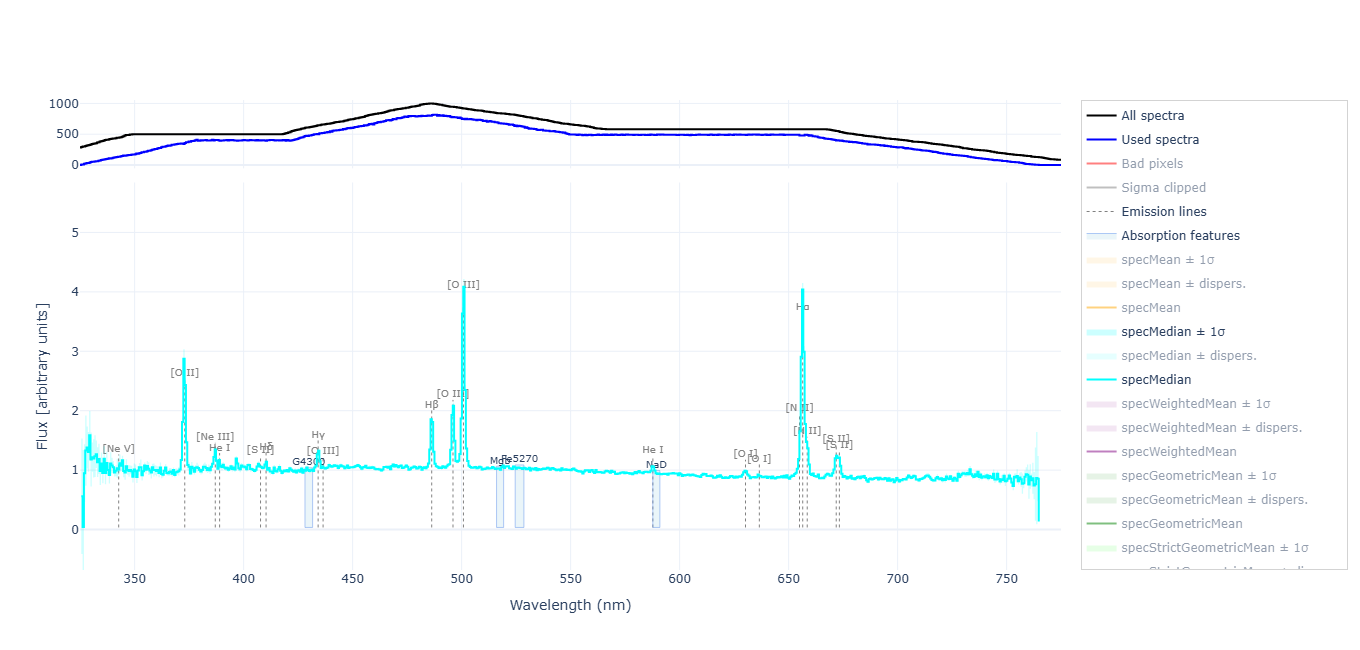

In [20]:
from spectraPyle.plot.plot import plotting

fig = plotting(f"{stack_file}.fits", width=1100, height=650)

###  2D flux distribution

The intermediate HDF5 file contains the resampled individual spectra before they are combined.  
The heatmap below shows the distribution of flux values across the input spectra at each wavelength, with the median stack overlaid.

#### Customizing the heatmap

The appearance and range of the heatmap can be adjusted through the optional arguments of `plot_h5_heatmap`.   
To inspect the available parameters and their default values, run in a cell:

```python
from spectraPyle.plot.plot import plot_h5_heatmap
plot_h5_heatmap?
```

Then modify the arguments in the function call below as needed.

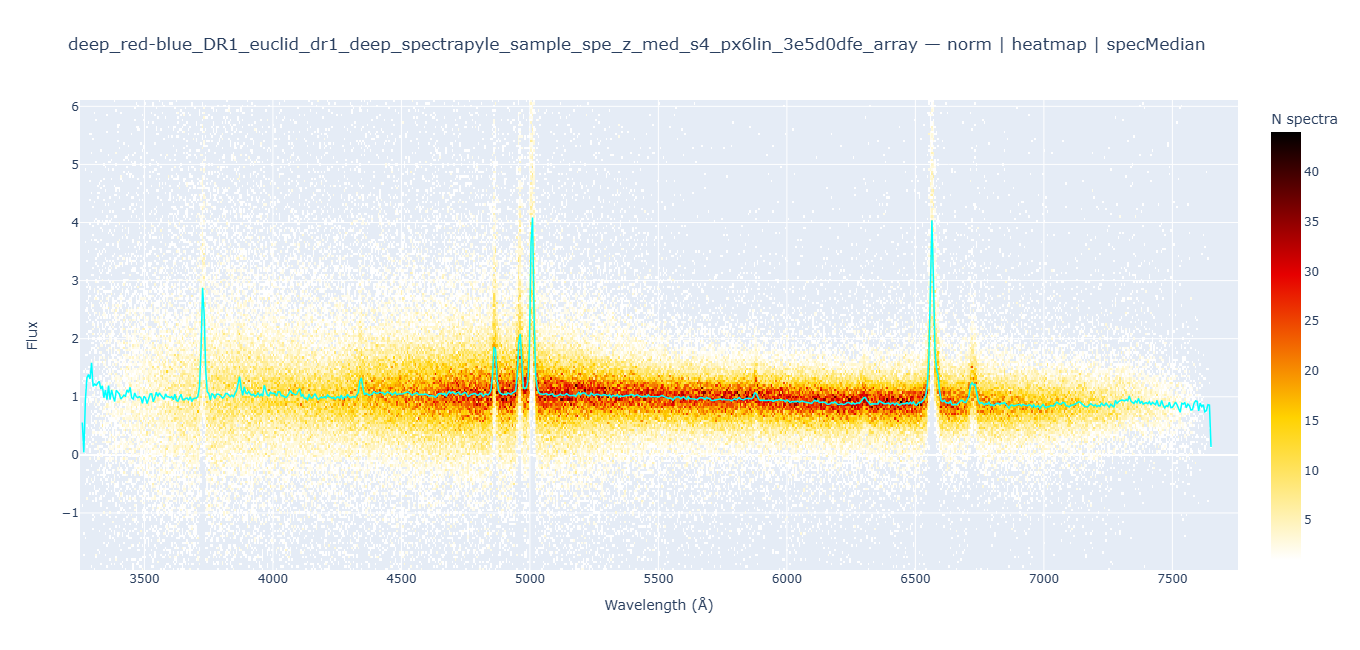

In [21]:
from spectraPyle.plot.plot import plot_h5_heatmap


fig = plot_h5_heatmap(
    h5_path=f"{stack_file}_array.h5",
    fits_path=f"{stack_file}.fits",
    metric="specMedian",
    mode="heatmap",
)

fig.show()

## 7. Further documentation

The complete **spectraPyle documentation**, including installation, configuration, processing options, and usage examples, is available [here](https://spectrapyle.readthedocs.io/en/latest/index.html).

For additional guidance, see:

- the [DataLabs-specific documentation](https://spectrapyle.readthedocs.io/en/latest/datalabs.html), covering the use of spectraPyle within the Euclid DataLabs environment;
- the complete [GUI tour](https://spectrapyle.readthedocs.io/en/latest/gui-tour.html), providing a detailed overview of the graphical interface and its configuration options.

For the latest releases and source code, visit the [spectraPyle GitHub repository](https://github.com/squai/SpectraPyle).